# TrustHire — results

Every number below is loaded from `results/` (real runs). Synthetic smoke-test outputs (`results/SYNTHETIC_DEMO`) are deliberately excluded.

In [1]:
import json, pathlib
import pandas as pd
import matplotlib.pyplot as plt
R = pathlib.Path('..') / 'results'
load = lambda p: json.loads((R / p).read_text()) if (R / p).exists() else None

## Voice anti-spoofing (public data)

In [2]:
b = load('audio/benchmark.json')
df = pd.DataFrame(b.values())[['dataset','condition','backend','n','auc','eer','tpr_at_fpr1','ece']]
df['eer_%'] = (100*df.eer).round(2); df.sort_values(['dataset','condition','eer'])

,dataset,condition,backend,n,auc,eer,tpr_at_fpr1,ece,eer_%
2,asv19la,clean,spectra0,308,1.000000,0.000000,1.000000,0.001560,0.00
3,asv19la,clean,spectra0_int8,308,1.000000,0.000000,1.000000,0.001681,0.00
0,asv19la,clean,aasist,308,0.998313,0.016234,0.941558,0.044514,1.62
1,asv19la,clean,aasist_l,308,0.999199,0.022727,0.980519,0.025609,2.27
6,itw,clean,spectra0,400,0.997750,0.012500,0.980000,0.023272,1.25
7,itw,clean,spectra0_int8,400,0.997725,0.012500,0.980000,0.022400,1.25
4,itw,clean,aasist,400,0.579450,0.425000,0.020000,0.296047,42.50
5,itw,clean,aasist_l,400,0.617488,0.435000,0.050000,0.324540,43.50
9,itw,mp3_32k,spectra0_int8,400,0.998575,0.022500,0.980000,0.047510,2.25
8,itw,mp3_32k,aasist,400,0.567913,0.417500,0.020000,0.303682,41.75


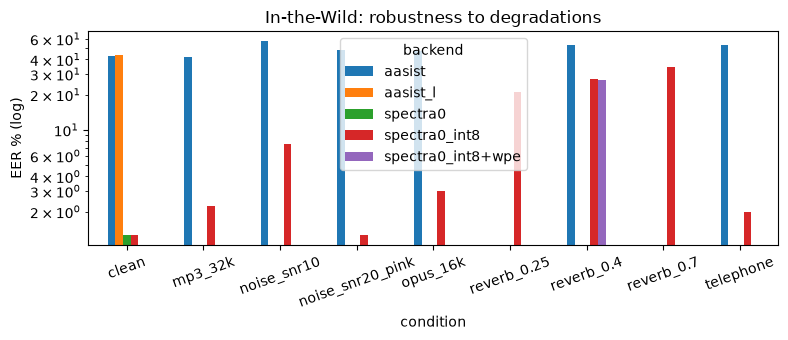

In [3]:
rob = df[df.dataset=='itw'].pivot(index='condition', columns='backend', values='eer_%')
ax = rob.plot.bar(figsize=(8,3.5), logy=True, rot=20); ax.set_ylabel('EER % (log)'); ax.set_title('In-the-Wild: robustness to degradations'); plt.tight_layout()

## Identity

In [4]:
f = load('identity/face_lfw.json'); s = load('identity/speaker_librispeech.json')
pd.DataFrame([{k: d.get(k) for k in ['benchmark','n','auc','eer','eer_threshold_sim']} for d in (f, s) if d])

,benchmark,n,auc,eer,eer_threshold_sim
0,LFW test pairs,1000,0.986040,0.030,0.121415
1,LibriSpeech test-clean trials (4 s segments),2000,0.998309,0.018,0.283640


## AV sync desync study

In [5]:
a = load('avsync/desync_study.json')
pd.DataFrame(a['per_shift']).T if a else 'pending'

,offset_acc_1f,mean_conf,mean_risk
-10,1.0,5.994692,1.000000
-6,1.0,9.221517,0.750013
-4,1.0,9.011472,0.250068
-2,1.0,8.747103,0.000235
0,1.0,8.807662,0.000235
2,1.0,8.779214,0.000211
4,1.0,8.742321,0.250092
6,1.0,8.798248,0.750029
10,1.0,8.841709,1.000000


## Latency (per 3 s window)

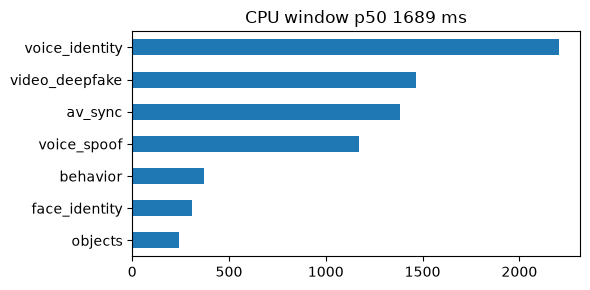

In [6]:
l = load('latency/latency_cpu.json')
pd.Series(l['modules_ms_p50']).sort_values().plot.barh(figsize=(6,3), title=f"CPU window p50 {l['total_ms_p50']:.0f} ms"); plt.tight_layout()

## Custom interview test set (ablations)

In [7]:
c = load('custom/results.json')
if c and not c['synthetic']:
    rows = [{'config': v['config'], 'fuser': v['fuser'], **{k: v['window'][k] for k in ('auc','eer','tpr_at_fpr5','ece')}} for v in c['ablation'].values()]
    display(pd.DataFrame(rows).sort_values('auc', ascending=False))
else:
    print('pending: record the custom set (docs/DATA_COLLECTION.md) and run `make eval-custom`')

pending: record the custom set (docs/DATA_COLLECTION.md) and run `make eval-custom`
